# 04 - Comparacao entre bancos e aprendizado

Este notebook existe para a apresentacao. Ele mostra como cada banco mede uma coisa diferente:

- Stack Overflow: respondentes desenvolvedores.
- StatCounter: participacao desktop observada por page views.
- Steam: usuarios da Steam/gamers na pesquisa de hardware/software.

A ideia nao e provar causalidade. A ideia e destacar uma mudanca interessante: Linux cresce nas tres leituras, mas com metodologias diferentes.

In [1]:
from pathlib import Path
import sys
import duckdb
import pandas as pd
from IPython.display import Image, display

def find_project_root(start=Path.cwd()):
    for path in (start, *start.parents):
        if (path / 'src').exists() and (path / 'data').exists():
            return path
    raise RuntimeError('Abra o notebook dentro do projeto os-data-project.')

root = find_project_root()
sys.path.insert(0, str(root / 'src'))
print(root)

/home/vini/Documentos/projetos/adoção-custo-de-so/os-data-project


## 1. Stack Overflow: desenvolvedores

Aqui o denominador e: respondentes que responderam validamente a pergunta de sistema operacional naquele ano. Como a resposta pode ser multipla, os percentuais podem somar mais de 100%.

In [2]:
con = duckdb.connect(str(root / 'data' / 'processed' / 'project.duckdb'), read_only=True)
stackoverflow = con.execute('''
WITH denom AS (
    SELECT survey_year,
           count(DISTINCT survey_year::VARCHAR || ':' || respondent_id) AS valid_respondents
    FROM survey_operating_systems
    GROUP BY survey_year
)
SELECT os.survey_year AS ano,
       os.operating_system_family AS sistema,
       count(DISTINCT os.survey_year::VARCHAR || ':' || os.respondent_id) AS respondentes,
       round(count(DISTINCT os.survey_year::VARCHAR || ':' || os.respondent_id) * 100.0 / denom.valid_respondents, 2) AS percentual
FROM survey_operating_systems os
JOIN denom USING (survey_year)
WHERE os.operating_system_family IN ('Windows', 'Linux', 'macOS')
GROUP BY os.survey_year, os.operating_system_family, denom.valid_respondents
ORDER BY os.survey_year, os.operating_system_family
''').df()
display(stackoverflow)

,ano,sistema,respondentes,percentual
0,2022,Linux,28523,43.54
1,2022,Windows,36674,55.99
2,2022,macOS,23578,36.00
3,2023,Linux,35906,45.69
4,2023,Windows,42844,54.52
5,2023,macOS,28786,36.63
6,2024,Linux,25167,47.51
7,2024,Windows,29365,55.43
8,2024,macOS,18625,35.16
9,2025,Linux,14649,50.72


## 2. Valores que explicam a mudanca

Esses valores estavam sendo tratados como `Other`, mas sao Linux. Esse foi o aprendizado mais importante da limpeza.

In [3]:
linux_variants = con.execute('''
SELECT survey_year AS ano,
       operating_system_original AS valor_original,
       count(*) AS selecoes
FROM survey_operating_systems
WHERE operating_system_original IN (
    'Other Linux-based',
    'Linux (non-WSL)',
    'Red Hat',
    'NixOS',
    'Pop!_OS'
)
GROUP BY survey_year, operating_system_original
ORDER BY survey_year, selecoes DESC, operating_system_original
''').df()
display(linux_variants)
print('Total reclassificado:', int(linux_variants['selecoes'].sum()))

,ano,valor_original,selecoes
0,2023,Other Linux-based,6712
1,2023,Red Hat,4043
2,2024,Other Linux-based,4697
3,2024,Red Hat,2858
4,2025,Linux (non-WSL),5261
5,2025,Red Hat,1789
6,2025,NixOS,570
7,2025,Pop!_OS,338


Total reclassificado: 26268


## 3. StatCounter: desktop geral

Esta fonte nao mede desenvolvedores. Ela mede market share desktop observado pela metodologia do StatCounter.

In [4]:
statcounter = con.execute('''
SELECT year(date) AS ano,
       operating_system_family AS sistema,
       round(avg(market_share), 2) AS percentual
FROM os_market_share
WHERE operating_system_family IN ('Windows', 'Linux', 'macOS')
  AND year(date) BETWEEN 2022 AND 2025
GROUP BY year(date), operating_system_family
ORDER BY ano, sistema
''').df()
con.close()
display(statcounter)

,ano,sistema,percentual
0,2022,Linux,2.69
1,2022,Windows,79.05
2,2022,macOS,7.93
3,2023,Linux,3.24
4,2023,Windows,73.18
5,2023,macOS,9.98
6,2024,Linux,4.38
7,2024,Windows,77.34
8,2024,macOS,8.03
9,2025,Linux,4.16


## 4. Steam: gamers

A Steam entra como fonte complementar. O notebook usa o script `src/investigate_gaming_linux.py`, que baixa os CSVs historicos e calcula Windows, Linux e macOS em dezembro de cada ano.

In [5]:
from investigate_gaming_linux import (
    SHS_CSV_URL,
    SHS_PLATFORM_CSV_URL,
    SYSTEMS,
    YEARS,
    build_main_os_map,
    build_platform_os_map,
    download_csv,
    estimate_system_share,
)

shs_rows, shs_size = download_csv(SHS_CSV_URL)
platform_rows, platform_size = download_csv(SHS_PLATFORM_CSV_URL)
main_os = build_main_os_map(shs_rows)
platform_os = build_platform_os_map(platform_rows)

steam_rows = []
for year in YEARS:
    for system in SYSTEMS:
        estimate = estimate_system_share(f'{year}-12-01', system, main_os, platform_os)
        steam_rows.append({
            'ano': year,
            'sistema': system,
            'percentual': round(estimate.pct, 2),
            'versoes_cruzadas': estimate.matched_versions,
        })
steam = pd.DataFrame(steam_rows)
display(steam)
print(f'Tamanho shs.csv: {shs_size / 1_000_000:.2f} MB')
print(f'Tamanho shs_platform.csv: {platform_size / 1_000_000:.2f} MB')

,ano,sistema,percentual,versoes_cruzadas
0,2022,Windows,96.14,5
1,2022,Linux,1.38,4
2,2022,macOS,2.45,13
3,2023,Windows,96.41,6
4,2023,Linux,1.94,4
5,2023,macOS,1.62,7
6,2024,Windows,96.33,3
7,2024,Linux,2.05,6
8,2024,macOS,1.40,6
9,2025,Windows,94.23,3


Tamanho shs.csv: 4.10 MB
Tamanho shs_platform.csv: 26.99 MB


## 5. Possiveis motivos ou caminhos de investigacao

O projeto nao prova causa, mas os dados ajudam a levantar explicacoes defensaveis:

- No Stack Overflow, parte da mudanca veio da normalizacao: respostas explicitamente Linux estavam em `Other`.
- No Stack Overflow 2025 aparece `Linux (non-WSL)`, o que deixa a resposta Linux mais explicita.
- Na Steam, existe uma presenca grande de SteamOS Holo dentro dos usuarios Linux, entao SteamOS/Steam Deck e ecossistema de jogos em Linux viram um caminho natural para investigar.
- No StatCounter, Linux tambem cresce no desktop geral, mas em escala bem menor que entre desenvolvedores.

In [6]:
# Participacao de SteamOS Holo dentro dos usuarios Linux da Steam, nao do total da Steam.
linux_platform = build_platform_os_map(platform_rows)
steamos = []
for year in YEARS:
    values = linux_platform[(f'{year}-12-01', 'linux')]
    holo = sum(pct for name, pct in values.items() if 'SteamOS Holo' in name) * 100
    steamos.append({'ano': year, 'SteamOS_Holo_dentro_do_Linux_%': round(holo, 2)})
display(pd.DataFrame(steamos))

,ano,SteamOS_Holo_dentro_do_Linux_%
0,2022,24.07
1,2023,40.53
2,2024,35.59
3,2025,26.32


## 6. Graficos prontos para print

Estes graficos ja foram gerados pelos scripts do projeto.

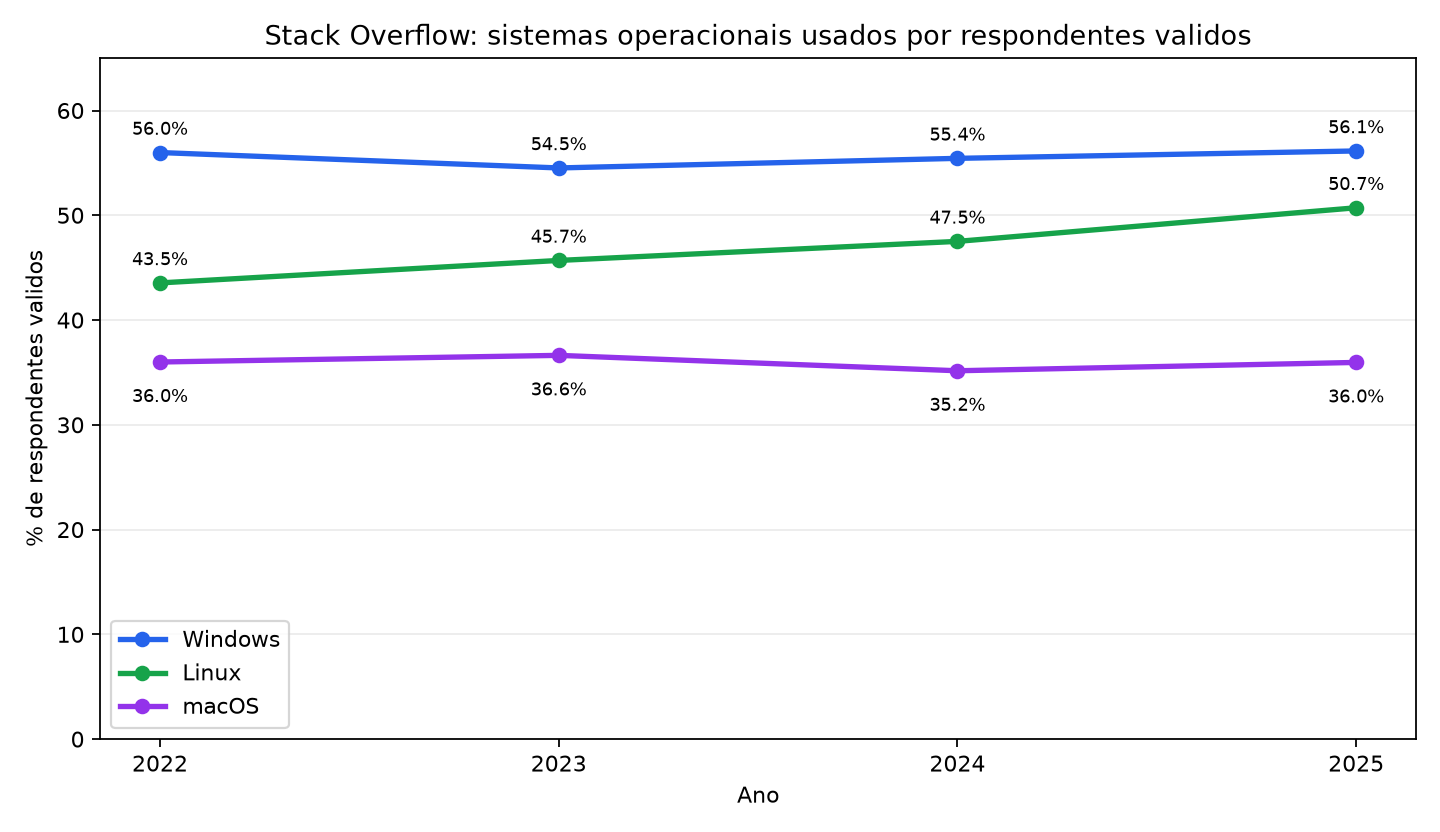

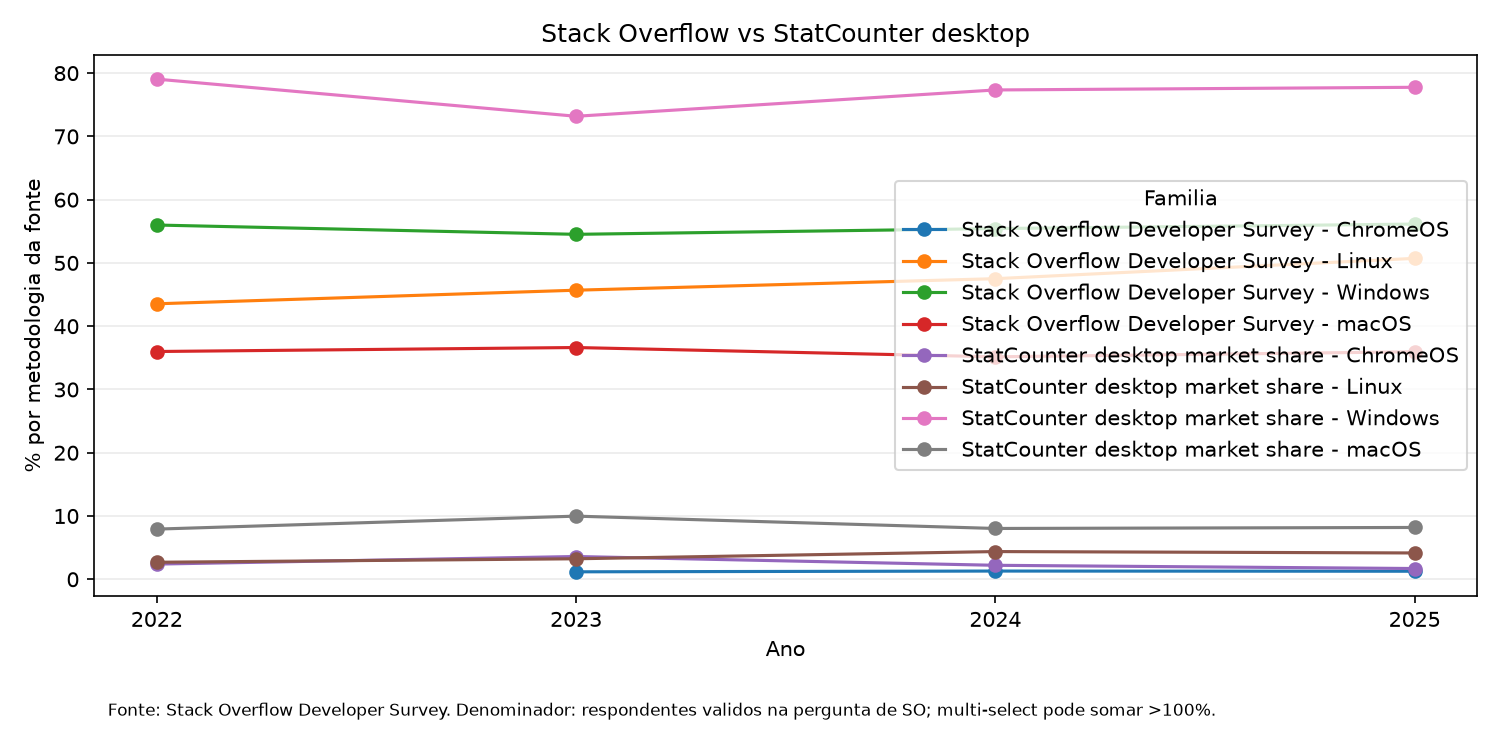

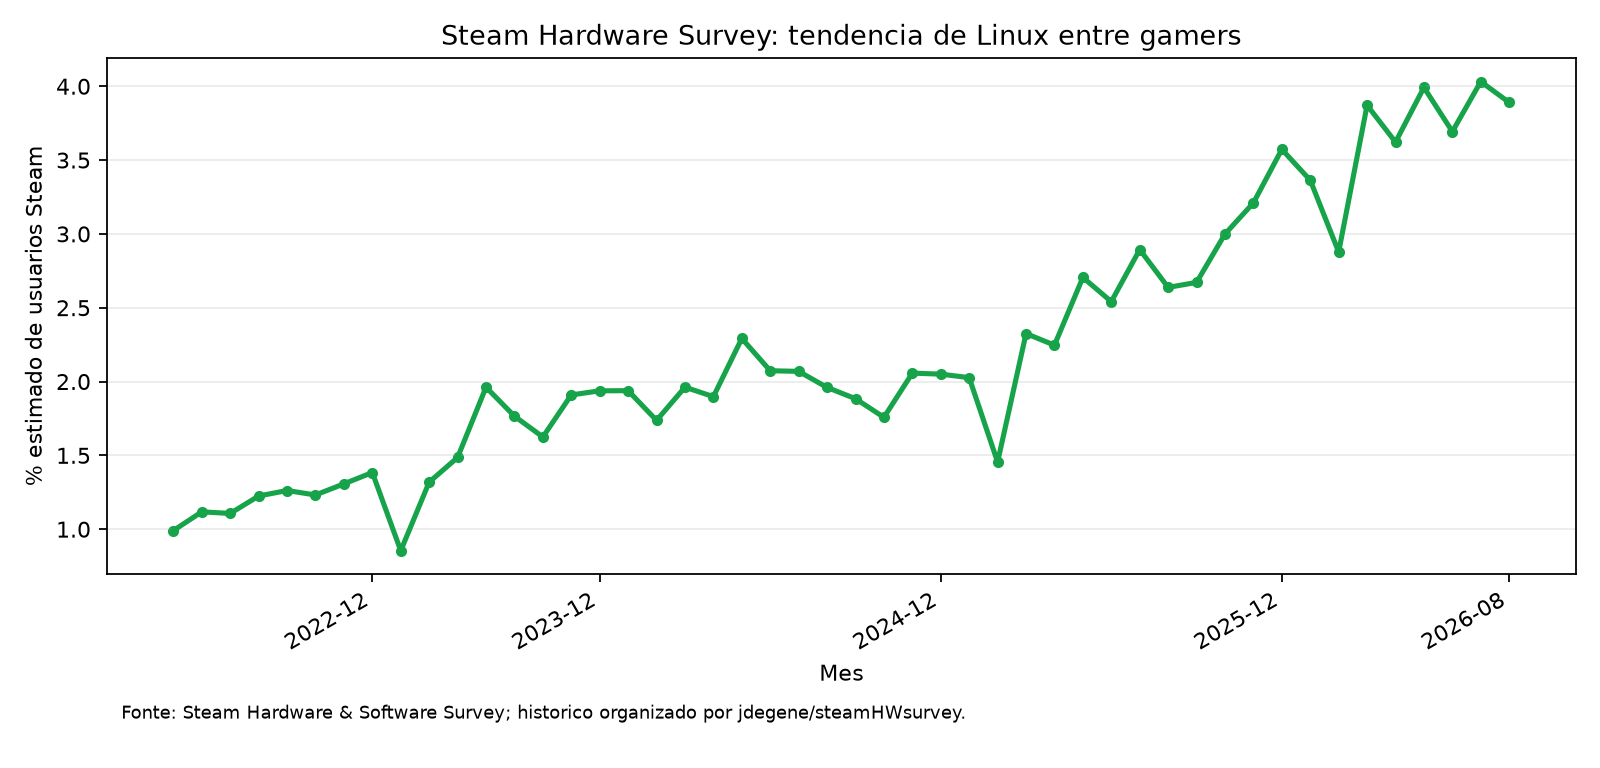

In [7]:
display(Image(filename=str(root / 'reports' / 'figures' / '06_trend_investigation.png')))
display(Image(filename=str(root / 'reports' / 'figures' / '04_stackoverflow_vs_statcounter.png')))
display(Image(filename=str(root / 'reports' / 'figures' / '07_steam_linux_trend.png')))

## 7. Frase para apresentar

`A gente aprendeu que comparar bancos exige entender a metodologia de cada um. Stack Overflow, StatCounter e Steam nao medem a mesma populacao. Mesmo assim, depois da limpeza correta, as tres fontes apontam crescimento de Linux. A parte mais importante do trabalho foi perceber que a preparacao dos dados mudava a conclusao.`